In [1]:
!pip install -U jiwer statsmodels transformers datasets soundfile librosa

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 35.5 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
  Attempting uninstall: librosa
    Found existing installation: librosa 0.11.0
    Uninstalling librosa-0.11.0:
      Successfully uninstalled librosa-0.11.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Su

In [1]:
import os, re, ast, random
import numpy as np
import pandas as pd
from jiwer import wer, cer
from scipy.stats import spearmanr
from statsmodels.stats.contingency_tables import mcnemar

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
updated_df = pd.read_csv("/content/drive/MyDrive/Brock_University/pidgindataset2026October/metadata_version2.0.csv")

In [3]:
base = "/content/drive/MyDrive/Brock_University/pidgindataset2026October/"

whisper_path = base + "outputRecent/Whisper_test_predictions.csv"
medasr_path  = base + "outputRecent/MedASR_test_predictions.csv"
canary_path  = base + "outputRecent/Canary_test_predictions.csv"

whisper_df = pd.read_csv(whisper_path)
medasr_df  = pd.read_csv(medasr_path)
canary_df  = pd.read_csv(canary_path)

In [6]:
# ============================================================
# FILL ONLY MISSING FEATURE VALUES FROM UPDATED DATASET
# ============================================================

feature_cols = [
    "speech_rate",
    "signal_to_noise_ratio",
    "silence_ratio",
]


def fill_missing_from_updated(
    model_df,
    updated_df,
    columns,
    key="sample_id"
):
    df = model_df.copy()

    lookup = (
        updated_df[
            [key] + columns
        ]
        .drop_duplicates(subset=key)
        .set_index(key)
    )

    df = df.set_index(key)

    for col in columns:

        if col not in df.columns:
            df[col] = np.nan

        if col not in lookup.columns:
            print(
                f"WARNING: {col} not found "
                f"in updated_df"
            )
            continue

        missing_before = (
            df[col].isna().sum()
        )

        # Fill ONLY NaN cells
        df[col] = df[col].fillna(
            lookup[col]
        )

        missing_after = (
            df[col].isna().sum()
        )

        print(
            f"{col}: "
            f"{missing_before} -> "
            f"{missing_after} NaN"
        )

    return df.reset_index()

In [7]:
print("WHISPER")
whisper_df = fill_missing_from_updated(
    whisper_df,
    updated_df,
    feature_cols
)


print("\nMEDASR")
medasr_df = fill_missing_from_updated(
    medasr_df,
    updated_df,
    feature_cols
)


print("\nCANARY")
canary_df = fill_missing_from_updated(
    canary_df,
    updated_df,
    feature_cols
)

WHISPER
speech_rate: 232 -> 0 NaN
signal_to_noise_ratio: 232 -> 0 NaN
silence_ratio: 232 -> 0 NaN

MEDASR
speech_rate: 232 -> 0 NaN
signal_to_noise_ratio: 232 -> 0 NaN
silence_ratio: 232 -> 0 NaN

CANARY
speech_rate: 232 -> 0 NaN
signal_to_noise_ratio: 232 -> 0 NaN
silence_ratio: 232 -> 0 NaN


In [4]:
for name, df in {
    "whisper_df": whisper_df,
    "medasr_df": medasr_df,
    "canary_df": canary_df,
}.items():

    print(f"\n{name}")
    print("-" * 40)

    print("Any NaN:", df.isna().any().any())

    nan_counts = df.isna().sum()

    print(
        nan_counts[
            nan_counts > 0
        ]
    )


whisper_df
----------------------------------------
Any NaN: True
medical_exact_correct    28
medical_recall           28
mwer                     28
dtype: int64

medasr_df
----------------------------------------
Any NaN: True
medical_exact_correct    28
medical_recall           28
mwer                     28
dtype: int64

canary_df
----------------------------------------
Any NaN: True
prediction               306
medical_exact_correct     28
medical_recall            28
mwer                      28
dtype: int64


In [5]:
whisper_df.head()

,sample_id,audio_path,audio_filepath,speaker_id,pidgin_transcription,reference,prediction,medical_terms,reference_medical_terms,predicted_medical_terms,...,medical_recall,wer,cer,mwer,model,audio_length,speech_rate,signal_to_noise_ratio,silence_ratio,medical_terms_pidgen
0,0007eceea7445996cb66,root/audio/Speaker_17/Speaker17-129.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_17,"Hello, e fit be some age-related cortical chan...",hello e fit be some age related cortical chang...,how far e fit be some age related critical cha...,"['cortical changes', 'computed tomography', 'n...","['computed tomography', 'cortical changes', 'd...","['computed tomography', 'normal']",...,0.500000,0.130435,0.058577,0.500000,Whisper-large-v3,23.17,1.942114,20.930300,0.084358,"['cortical changes', 'computed tomography', 'n..."
1,001275179d737b980aab,root/audio/Speaker_6/Speaker6-372.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_6,after dem pull all my remaining teeth for lowe...,after dem pull all my remaining teeth for lowe...,after dem pull all my remaining teeth for lowe...,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum...","['appointment never reach', 'cyst', 'hospital'...","['appointment never reach', 'cyst', 'hospital'...",...,1.000000,0.043478,0.020528,0.000000,Whisper-large-v3,26.17,2.636720,30.567606,0.185597,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum..."
2,00197304cdccf249be4e,root/audio/Speaker_6/Speaker6-415.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_6,my son na five months old and he don dey make ...,my son na five months old and he don dey make ...,my son na five months old and he don dey make ...,"['son', 'five months old', 'catarrh phlegm ful...","['carry', 'catarrh phlegm full', 'chest', 'cry...","['carry', 'chest', 'cry', 'five months old', '...",...,0.727273,0.225806,0.151376,0.333333,Whisper-large-v3,32.35,2.875212,12.604013,0.004947,"['son', 'five months old', 'catarrh phlegm ful..."
3,0023b3f0f2acb32f7772,root/audio/Speaker_6/Speaker6-174.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_6,go see lung doctor pulmonologist make dem do c...,go see lung doctor pulmonologist make dem do c...,go see lung doctor make dem do chest x ray spi...,"['lung', 'chest x ray spirometry breathing tes...","['chest x ray spirometry breathing test', 'ful...","['full blood count', 'lower airway sickness', ...",...,0.750000,0.107143,0.189542,0.461538,Whisper-large-v3,10.52,2.661945,21.914759,0.097351,"['lung', 'chest x ray spirometry breathing tes..."
4,002922c6c57a34d7f082,root/audio/Speaker_1/Speaker1-157.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_1,a couple of days ago my pulse rate dey fifty e...,a couple of days ago my pulse rate dey fifty e...,a couple of days ago my pulse rate dey now wey...,"['a couple of days ago', 'pulse rate dey fifty...","['a couple of days ago', 'cold', 'decongestant...","['a couple of days ago', 'cold', 'decongestant...",...,0.700000,0.140351,0.120996,0.363636,Whisper-large-v3,25.96,2.195411,48.897175,0.281446,"['a couple of days ago', 'pulse rate dey fifty..."


#Spearman-Correlation

In [6]:
import ast
import pandas as pd

def parse_terms(x):
    if isinstance(x, list):
        return x
    if pd.isna(x):
        return []
    if isinstance(x, str):
        x = x.strip()
        if x == "" or x in ["[]", "[ ]"]:
            return []
        try:
            parsed = ast.literal_eval(x)
            if isinstance(parsed, list):
                return parsed
        except:
            return []
    return []

medasr_df["medical_terms_pidgen"] = medasr_df["medical_terms_pidgen"].apply(parse_terms)

medasr_df = medasr_df[medasr_df["medical_terms_pidgen"].apply(len) > 0].copy()

print("Remaining rows:", len(medasr_df))

Remaining rows: 2223


In [7]:
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def parse_terms(x):
    if isinstance(x, list):
        terms = x
    elif pd.isna(x):
        terms = []
    elif isinstance(x, str):
        x = x.strip()
        if x in ["", "[]", "nan", "None", "null"]:
            terms = []
        else:
            try:
                terms = ast.literal_eval(x)
                if not isinstance(terms, list):
                    terms = [terms]
            except:
                terms = [t.strip() for t in x.split(",") if t.strip()]
    else:
        terms = []

    return [normalize_text(t) for t in terms if normalize_text(t)]

In [8]:
features = [
    "audio_length",
    "speech_rate",
    "signal_to_noise_ratio",
    "silence_ratio",
    "english_ratio",
    "pidgin_ratio",
    "cmi"
]

def spearman_analysis(df, model_name):
    rows = []

    for feature in features:
        if feature not in df.columns:
            continue

        for metric in ["wer", "cer", "mwer"]:
            if metric not in df.columns:
                continue

            temp = df[[feature, metric]].dropna()

            if len(temp) < 3:
                continue

            rho, p_value = spearmanr(temp[feature], temp[metric])

            rows.append({
                "model": model_name,
                "feature": feature,
                "metric": metric,
                "spearman_rho": rho,
                "p_value": p_value,
                "n": len(temp)
            })

    return pd.DataFrame(rows)

spearman_results = pd.concat([
    spearman_analysis(whisper_df, "Whisper"),
    spearman_analysis(medasr_df, "MedASR"),
    spearman_analysis(canary_df, "Canary")
], ignore_index=True)

spearman_results

,model,feature,metric,spearman_rho,p_value,n
0,Whisper,audio_length,wer,0.697647,0.000000e+00,2245
1,Whisper,audio_length,cer,0.722882,0.000000e+00,2245
2,Whisper,audio_length,mwer,0.400048,5.539107e-86,2217
3,Whisper,speech_rate,wer,-0.339447,1.168146e-61,2245
4,Whisper,speech_rate,cer,-0.259887,5.608163e-36,2245
5,Whisper,speech_rate,mwer,-0.262220,3.500648e-36,2217
6,Whisper,signal_to_noise_ratio,wer,0.159605,2.806967e-14,2245
7,Whisper,signal_to_noise_ratio,cer,0.102601,1.107247e-06,2245
8,Whisper,signal_to_noise_ratio,mwer,0.155995,1.511721e-13,2217
9,Whisper,silence_ratio,wer,0.210512,6.637617e-24,2245


In [9]:
import numpy as np
import pandas as pd

# -----------------------------
# 1. Add interpretation columns
# -----------------------------

def strength_label(rho):
    if pd.isna(rho):
        return "NA"

    abs_rho = abs(rho)

    if abs_rho < 0.10:
        return "negligible"
    elif abs_rho < 0.30:
        return "weak"
    elif abs_rho < 0.50:
        return "moderate"
    else:
        return "strong"

def direction_label(rho):
    if pd.isna(rho):
        return "NA"
    elif rho > 0:
        return "positive"
    elif rho < 0:
        return "negative"
    else:
        return "none"

def significance_label(p):
    if pd.isna(p):
        return "NA"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

spearman_analysis_df = spearman_results.copy()

spearman_analysis_df["strength"] = spearman_analysis_df["spearman_rho"].apply(strength_label)
spearman_analysis_df["direction"] = spearman_analysis_df["spearman_rho"].apply(direction_label)
spearman_analysis_df["significance"] = spearman_analysis_df["p_value"].apply(significance_label)
spearman_analysis_df["significant"] = spearman_analysis_df["p_value"] < 0.05

spearman_analysis_df["rho_formatted"] = spearman_analysis_df.apply(
    lambda row: f"{row['spearman_rho']:.3f}{row['significance']}",
    axis=1
)

spearman_analysis_df

,model,feature,metric,spearman_rho,p_value,n,strength,direction,significance,significant,rho_formatted
0,Whisper,audio_length,wer,0.697647,0.000000e+00,2245,strong,positive,***,True,0.698***
1,Whisper,audio_length,cer,0.722882,0.000000e+00,2245,strong,positive,***,True,0.723***
2,Whisper,audio_length,mwer,0.400048,5.539107e-86,2217,moderate,positive,***,True,0.400***
3,Whisper,speech_rate,wer,-0.339447,1.168146e-61,2245,moderate,negative,***,True,-0.339***
4,Whisper,speech_rate,cer,-0.259887,5.608163e-36,2245,weak,negative,***,True,-0.260***
5,Whisper,speech_rate,mwer,-0.262220,3.500648e-36,2217,weak,negative,***,True,-0.262***
6,Whisper,signal_to_noise_ratio,wer,0.159605,2.806967e-14,2245,weak,positive,***,True,0.160***
7,Whisper,signal_to_noise_ratio,cer,0.102601,1.107247e-06,2245,weak,positive,***,True,0.103***
8,Whisper,signal_to_noise_ratio,mwer,0.155995,1.511721e-13,2217,weak,positive,***,True,0.156***
9,Whisper,silence_ratio,wer,0.210512,6.637617e-24,2245,weak,positive,***,True,0.211***


In [10]:
meaningful_results = spearman_analysis_df[
    (spearman_analysis_df["significant"]) &
    (spearman_analysis_df["strength"].isin(["weak", "moderate", "strong"]))
].copy()

meaningful_results = meaningful_results.sort_values(
    by=["model", "metric", "spearman_rho"],
    key=lambda x: abs(x) if x.name == "spearman_rho" else x,
    ascending=False
)

meaningful_results

,model,feature,metric,spearman_rho,p_value,n,strength,direction,significance,significant,rho_formatted
0,Whisper,audio_length,wer,0.697647,0.000000e+00,2245,strong,positive,***,True,0.698***
3,Whisper,speech_rate,wer,-0.339447,1.168146e-61,2245,moderate,negative,***,True,-0.339***
9,Whisper,silence_ratio,wer,0.210512,6.637617e-24,2245,weak,positive,***,True,0.211***
6,Whisper,signal_to_noise_ratio,wer,0.159605,2.806967e-14,2245,weak,positive,***,True,0.160***
2,Whisper,audio_length,mwer,0.400048,5.539107e-86,2217,moderate,positive,***,True,0.400***
5,Whisper,speech_rate,mwer,-0.262220,3.500648e-36,2217,weak,negative,***,True,-0.262***
11,Whisper,silence_ratio,mwer,0.193946,3.129032e-20,2217,weak,positive,***,True,0.194***
8,Whisper,signal_to_noise_ratio,mwer,0.155995,1.511721e-13,2217,weak,positive,***,True,0.156***
1,Whisper,audio_length,cer,0.722882,0.000000e+00,2245,strong,positive,***,True,0.723***
4,Whisper,speech_rate,cer,-0.259887,5.608163e-36,2245,weak,negative,***,True,-0.260***


In [11]:
paper_table = spearman_analysis_df.pivot_table(
    index=["model", "feature"],
    columns="metric",
    values="rho_formatted",
    aggfunc="first"
).reset_index()

paper_table = paper_table.rename(columns={
    "wer": "WER ρ",
    "cer": "CER ρ",
    "mwer": "mWER ρ"
})

paper_table

metric,model,feature,CER ρ,mWER ρ,WER ρ
0,Canary,audio_length,-0.021ns,-0.009ns,-0.032ns
1,Canary,signal_to_noise_ratio,0.182***,0.146***,0.263***
2,Canary,silence_ratio,0.215***,0.157***,0.289***
3,Canary,speech_rate,-0.089***,-0.157***,-0.196***
4,MedASR,audio_length,0.056**,0.114***,0.026ns
5,MedASR,signal_to_noise_ratio,0.293***,0.188***,0.364***
6,MedASR,silence_ratio,0.338***,0.212***,0.409***
7,MedASR,speech_rate,-0.088***,-0.169***,-0.226***
8,Whisper,audio_length,0.723***,0.400***,0.698***
9,Whisper,signal_to_noise_ratio,0.103***,0.156***,0.160***


In [16]:
top_predictors = (
    spearman_analysis_df
    .dropna(subset=["spearman_rho"])
    .assign(abs_rho=lambda x: x["spearman_rho"].abs())
    .sort_values(["model", "metric", "abs_rho"], ascending=[True, True, False])
    .groupby(["model", "metric"])
    .head(3)
    .reset_index(drop=True)
)

top_predictors[[
    "model", "metric", "feature", "spearman_rho",
    "p_value", "strength", "direction", "significance", "n"
]]

,model,metric,feature,spearman_rho,p_value,strength,direction,significance,n
0,Canary,cer,silence_ratio,0.212274,5.268359e-24,weak,positive,***,2217
1,Canary,cer,signal_to_noise_ratio,0.178689,2.308192e-17,weak,positive,***,2217
2,Canary,cer,speech_rate,-0.093435,1.050349e-05,negligible,negative,***,2217
3,Canary,mwer,silence_ratio,0.157333,9.312315e-14,weak,positive,***,2217
4,Canary,mwer,speech_rate,-0.157142,9.981308e-14,weak,negative,***,2217
5,Canary,mwer,signal_to_noise_ratio,0.145946,5.020496e-12,weak,positive,***,2217
6,Canary,wer,silence_ratio,0.287240,2.246230e-43,weak,positive,***,2217
7,Canary,wer,signal_to_noise_ratio,0.261270,6.343251e-36,weak,positive,***,2217
8,Canary,wer,speech_rate,-0.200108,1.849657e-21,weak,negative,***,2217
9,MedASR,cer,silence_ratio,0.338893,1.045950e-60,moderate,positive,***,2217


In [17]:
def feature_explanation(feature, direction, metric):
    if feature == "audio_length":
        return f"{'longer' if direction == 'positive' else 'shorter'} audio segments are associated with {'higher' if direction == 'positive' else 'lower'} {metric.upper()}."

    if feature == "speech_rate":
        return f"{'faster' if direction == 'positive' else 'slower'} speech is associated with {'higher' if direction == 'positive' else 'lower'} {metric.upper()}."

    if feature == "signal_to_noise_ratio":
        return f"{'higher' if direction == 'positive' else 'lower'} signal-to-noise ratio is associated with {'higher' if direction == 'positive' else 'lower'} {metric.upper()}."

    if feature == "silence_ratio":
        return f"{'more' if direction == 'positive' else 'less'} silence is associated with {'higher' if direction == 'positive' else 'lower'} {metric.upper()}."

    if feature == "english_ratio":
        return f"{'higher' if direction == 'positive' else 'lower'} English ratio is associated with {'higher' if direction == 'positive' else 'lower'} {metric.upper()}."

    if feature == "pidgin_ratio":
        return f"{'higher' if direction == 'positive' else 'lower'} Pidgin ratio is associated with {'higher' if direction == 'positive' else 'lower'} {metric.upper()}."

    if feature == "cmi":
        return f"{'higher' if direction == 'positive' else 'lower'} code-mixing index is associated with {'higher' if direction == 'positive' else 'lower'} {metric.upper()}."

    return f"{feature} is associated with {metric.upper()}."

def generate_interpretation(row):
    return (
        f"For {row['model']}, {row['feature']} shows a "
        f"{row['strength']} {row['direction']} correlation with {row['metric'].upper()} "
        f"(ρ = {row['spearman_rho']:.3f}, p = {row['p_value']:.4f}, n = {int(row['n'])}). "
        f"This suggests that {feature_explanation(row['feature'], row['direction'], row['metric'])}"
    )

interpretation_sentences = meaningful_results.copy()
interpretation_sentences["interpretation"] = interpretation_sentences.apply(
    generate_interpretation,
    axis=1
)

for sentence in interpretation_sentences["interpretation"].tolist():
    print(sentence)
    print()

For Whisper, audio_length shows a strong positive correlation with WER (ρ = 0.699, p = 0.0000, n = 2217). This suggests that longer audio segments are associated with higher WER.

For Whisper, speech_rate shows a moderate negative correlation with WER (ρ = -0.344, p = 0.0000, n = 2217). This suggests that slower speech is associated with lower WER.

For Whisper, silence_ratio shows a weak positive correlation with WER (ρ = 0.213, p = 0.0000, n = 2217). This suggests that more silence is associated with higher WER.

For Whisper, signal_to_noise_ratio shows a weak positive correlation with WER (ρ = 0.161, p = 0.0000, n = 2217). This suggests that higher signal-to-noise ratio is associated with higher WER.

For Whisper, audio_length shows a moderate positive correlation with MWER (ρ = 0.400, p = 0.0000, n = 2217). This suggests that longer audio segments are associated with higher MWER.

For Whisper, speech_rate shows a weak negative correlation with MWER (ρ = -0.262, p = 0.0000, n = 2217

In [18]:
output_dir = base + "Models_Results/spearman_analysis_outputs/"
os.makedirs(output_dir, exist_ok=True)

spearman_analysis_df.to_csv(
    os.path.join(output_dir, "spearman_full_results_interpreted.csv"),
    index=False
)

meaningful_results.to_csv(
    os.path.join(output_dir, "spearman_significant_meaningful_results.csv"),
    index=False
)

paper_table.to_csv(
    os.path.join(output_dir, "spearman_paper_table.csv"),
    index=False
)

top_predictors.to_csv(
    os.path.join(output_dir, "spearman_top_predictors.csv"),
    index=False
)

print("Saved outputs to:", output_dir)

Saved outputs to: /content/drive/MyDrive/Brock_University/pidgindataset2026October/Models_Results/spearman_analysis_outputs/


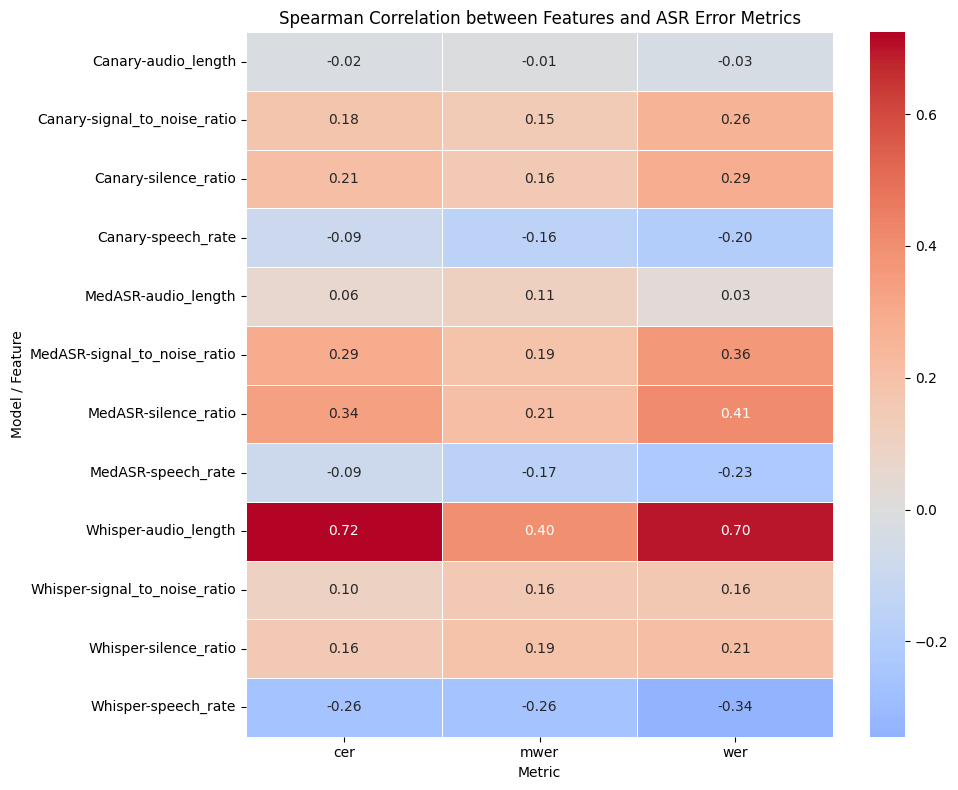

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pivot for heatmap
heatmap_df = spearman_analysis_df.pivot_table(
    index=["model", "feature"],
    columns="metric",
    values="spearman_rho"
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation between Features and ASR Error Metrics")
plt.ylabel("Model / Feature")
plt.xlabel("Metric")
plt.tight_layout()
plt.show()

In [20]:
whisper_df.head()

,sample_id,audio_path,audio_filepath,speaker_id,pidgin_transcription,reference,prediction,medical_terms,reference_medical_terms,predicted_medical_terms,...,medical_recall,wer,cer,mwer,model,audio_length,speech_rate,signal_to_noise_ratio,silence_ratio,medical_terms_pidgen
0,0007eceea7445996cb66,root/audio/Speaker_17/Speaker17-129.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_17,"Hello, e fit be some age-related cortical chan...",hello e fit be some age related cortical chang...,how far e fit be some age related critical cha...,"['cortical changes', 'computed tomography', 'n...","['computed tomography', 'cortical changes', 'd...","['computed tomography', 'normal']",...,0.500000,0.130435,0.058577,0.500000,Whisper-large-v3,23.17,1.942114,20.930300,0.084358,"['cortical changes', 'computed tomography', 'n..."
1,001275179d737b980aab,root/audio/Speaker_6/Speaker6-372.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_6,after dem pull all my remaining teeth for lowe...,after dem pull all my remaining teeth for lowe...,after dem pull all my remaining teeth for lowe...,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum...","['appointment never reach', 'cyst', 'hospital'...","['appointment never reach', 'cyst', 'hospital'...",...,1.000000,0.043478,0.020528,0.000000,Whisper-large-v3,26.17,2.636720,30.567606,0.185597,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum..."
2,00197304cdccf249be4e,root/audio/Speaker_6/Speaker6-415.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_6,my son na five months old and he don dey make ...,my son na five months old and he don dey make ...,my son na five months old and he don dey make ...,"['son', 'five months old', 'catarrh phlegm ful...","['carry', 'catarrh phlegm full', 'chest', 'cry...","['carry', 'chest', 'cry', 'five months old', '...",...,0.727273,0.225806,0.151376,0.333333,Whisper-large-v3,32.35,2.875212,12.604013,0.004947,"['son', 'five months old', 'catarrh phlegm ful..."
3,0023b3f0f2acb32f7772,root/audio/Speaker_6/Speaker6-174.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_6,go see lung doctor pulmonologist make dem do c...,go see lung doctor pulmonologist make dem do c...,go see lung doctor make dem do chest x ray spi...,"['lung', 'chest x ray spirometry breathing tes...","['chest x ray spirometry breathing test', 'ful...","['full blood count', 'lower airway sickness', ...",...,0.750000,0.107143,0.189542,0.461538,Whisper-large-v3,10.52,2.661945,21.914759,0.097351,"['lung', 'chest x ray spirometry breathing tes..."
4,002922c6c57a34d7f082,root/audio/Speaker_1/Speaker1-157.wav,/content/drive/MyDrive/Brock_University/pidgin...,Speaker_1,a couple of days ago my pulse rate dey fifty e...,a couple of days ago my pulse rate dey fifty e...,a couple of days ago my pulse rate dey now wey...,"['a couple of days ago', 'pulse rate dey fifty...","['a couple of days ago', 'cold', 'decongestant...","['a couple of days ago', 'cold', 'decongestant...",...,0.700000,0.140351,0.120996,0.363636,Whisper-large-v3,25.96,2.195411,48.897175,0.281446,"['a couple of days ago', 'pulse rate dey fifty..."


In [21]:
whisper_df[['audio_path', 'prediction', 'reference', 'medical_terms_pidgen']]

,audio_path,prediction,reference,medical_terms_pidgen
0,root/audio/Speaker_17/Speaker17-129.wav,how far e fit be some age related critical cha...,hello e fit be some age related cortical chang...,"['cortical changes', 'computed tomography', 'n..."
1,root/audio/Speaker_6/Speaker6-372.wav,after dem pull all my remaining teeth for lowe...,after dem pull all my remaining teeth for lowe...,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum..."
2,root/audio/Speaker_6/Speaker6-415.wav,my son na five months old and he don dey make ...,my son na five months old and he don dey make ...,"['son', 'five months old', 'catarrh phlegm ful..."
3,root/audio/Speaker_6/Speaker6-174.wav,go see lung doctor make dem do chest x ray spi...,go see lung doctor pulmonologist make dem do c...,"['lung', 'chest x ray spirometry breathing tes..."
4,root/audio/Speaker_1/Speaker1-157.wav,a couple of days ago my pulse rate dey now wey...,a couple of days ago my pulse rate dey fifty e...,"['a couple of days ago', 'pulse rate dey fifty..."
...,...,...,...,...
2212,root/audio/Speaker_4/Speaker4-22.wav,hello welcome to health care management i appr...,hello welcome to health care management i appr...,"['mama', 'bladder', 'flow', 'urethritis', 'inf..."
2213,root/audio/Speaker_6/Speaker6-388.wav,infection dey cause fast heartbeat like for vi...,infection dey cause fast heartbeat palpitation...,"['infections', 'heartbeat palpitations', 'unco..."
2214,root/audio/Speaker_1/Speaker1-339.wav,she get cholinalic butycaria hydroxyzine mg tw...,she get cholinergic urticaria hydroxyzine mg t...,"['cholinergic urticaria', 'mg twice a day go']"
2215,root/audio/Speaker_10/Speaker10-441.wav,i hit my head for my windshield during one acc...,i hit my head on my windshield during an accid...,"['emergency room', 'doctor', 'head', 'normal n..."


In [22]:
medasr_df[['audio_path', 'prediction', 'reference', 'medical_terms_pidgen']]

,audio_path,prediction,reference,medical_terms_pidgen
0,root/audio/Speaker_17/Speaker17-129.wav,howver e fit be some age related cortical chan...,hello e fit be some age related cortical chang...,"[cortical changes, computed tomography, normal..."
1,root/audio/Speaker_6/Speaker6-372.wav,after de impve all my remaining teeth for lowe...,after dem pull all my remaining teeth for lowe...,"[lower jaw, lump, cyst, hospital, lump reduce,..."
2,root/audio/Speaker_6/Speaker6-415.wav,my son na five months old and he don dey make ...,my son na five months old and he don dey make ...,"[son, five months old, catarrh phlegm full, ch..."
3,root/audio/Speaker_6/Speaker6-174.wav,go see lung doctor make dem do check x x ray s...,go see lung doctor pulmonologist make dem do c...,"[lung, chest x ray spirometry breathing test, ..."
4,root/audio/Speaker_1/Speaker1-157.wav,a couple of days ago my pulse rate day fift ei...,a couple of days ago my pulse rate dey fifty e...,"[a couple of days ago, pulse rate dey fifty ei..."
...,...,...,...,...
2212,root/audio/Speaker_4/Speaker4-22.wav,tell the welcome health caare management i p s...,hello welcome to health care management i appr...,"[mama, bladder, flow, urethritis, infections, ..."
2213,root/audio/Speaker_6/Speaker6-388.wav,infection dey cause fast heart beeat like for ...,infection dey cause fast heartbeat palpitation...,"[infections, heartbeat palpitations, uncomfort..."
2214,root/audio/Speaker_1/Speaker1-339.wav,she get tral nalig t caria hydroxyzin mg twice...,she get cholinergic urticaria hydroxyzine mg t...,"[cholinergic urticaria, mg twice a day go]"
2215,root/audio/Speaker_10/Speaker10-441.wav,i hit my head for my windsheet during accident...,i hit my head on my windshield during an accid...,"[emergency room, doctor, head, normal negative..."


In [23]:
canary_df[['audio_path', 'prediction', 'reference', 'medical_terms_pidgen']]

,audio_path,prediction,reference,medical_terms_pidgen
0,root/audio/Speaker_17/Speaker17-129.wav,how far e fit be some age related critical cha...,hello e fit be some age related cortical chang...,"['cortical changes', 'computed tomography', 'n..."
1,root/audio/Speaker_6/Speaker6-372.wav,NaN,after dem pull all my remaining teeth for lowe...,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum..."
2,root/audio/Speaker_6/Speaker6-415.wav,my son na five months old and he don dey make ...,my son na five months old and he don dey make ...,"['son', 'five months old', 'catarrh phlegm ful..."
3,root/audio/Speaker_6/Speaker6-174.wav,NaN,go see lung doctor pulmonologist make dem do c...,"['lung', 'chest x ray spirometry breathing tes..."
4,root/audio/Speaker_1/Speaker1-157.wav,a couple of days ago my pulse rate day fifty e...,a couple of days ago my pulse rate dey fifty e...,"['a couple of days ago', 'pulse rate dey fifty..."
...,...,...,...,...
2212,root/audio/Speaker_4/Speaker4-22.wav,hello welcome to healthcare management i appre...,hello welcome to health care management i appr...,"['mama', 'bladder', 'flow', 'urethritis', 'inf..."
2213,root/audio/Speaker_6/Speaker6-388.wav,NaN,infection dey cause fast heartbeat palpitation...,"['infections', 'heartbeat palpitations', 'unco..."
2214,root/audio/Speaker_1/Speaker1-339.wav,NaN,she get cholinergic urticaria hydroxyzine mg t...,"['cholinergic urticaria', 'mg twice a day go']"
2215,root/audio/Speaker_10/Speaker10-441.wav,i hit my head for my windshield during acciden...,i hit my head on my windshield during an accid...,"['emergency room', 'doctor', 'head', 'normal n..."


In [24]:
import pandas as pd
import ast
import re

if len(whisper_df) == len(canary_df):
    canary_df["audio_path"] = whisper_df["audio_path"].values
    print("audio_path copied from Whisper to Canary")
else:
    print("Length mismatch — cannot safely copy audio_path")


if "text" in canary_df.columns:
    canary_df = canary_df.rename(columns={"text": "reference"})
    print("'text' renamed to 'reference' in Canary")
else:
    print("'text' column not found in Canary")


def clean_medical_terms(x):
    if isinstance(x, list):
        terms = x
    elif pd.isna(x):
        return []
    elif isinstance(x, str):
        x = x.strip()

        # Try parsing string list
        try:
            parsed = ast.literal_eval(x)
            if isinstance(parsed, list):
                terms = parsed
            else:
                terms = [parsed]
        except:
            # fallback: split manually
            terms = [t.strip() for t in x.split(",")]
    else:
        return []

    # Normalize: remove quotes, spaces
    cleaned = [
        re.sub(r"[\"\'\[\]]", "", str(t)).strip()
        for t in terms if str(t).strip()
    ]

    return cleaned

# Apply to both datasets
whisper_df["medical_terms_pidgen"] = whisper_df["medical_terms_pidgen"].apply(clean_medical_terms)
canary_df["medical_terms_pidgen"]  = canary_df["medical_terms_pidgen"].apply(clean_medical_terms)

print("medical_terms cleaned for Whisper and Canary")

print("\nSample cleaned terms:")
print(whisper_df["medical_terms_pidgen"].head(3))
print(canary_df["medical_terms_pidgen"].head(3))

audio_path copied from Whisper to Canary
'text' column not found in Canary
medical_terms cleaned for Whisper and Canary

Sample cleaned terms:
0    [cortical changes, computed tomography, normal...
1    [lower jaw, lump, cyst, hospital, lump reduce,...
2    [son, five months old, catarrh phlegm full, ch...
Name: medical_terms_pidgen, dtype: object
0    [cortical changes, computed tomography, normal...
1    [lower jaw, lump, cyst, hospital, lump reduce,...
2    [son, five months old, catarrh phlegm full, ch...
Name: medical_terms_pidgen, dtype: object


In [25]:
def medical_exact_correct(row):
    ref = normalize_text(row["reference"])
    pred = normalize_text(row["prediction"])
    terms = parse_terms(row["medical_terms_pidgen"])

    ref_tokens = ref.split()
    pred_tokens = pred.split()

    def term_present(tokens, term):
        target = term.split()
        n = len(target)

        return any(
            tokens[i:i+n] == target
            for i in range(len(tokens) - n + 1)
        )

    ref_terms = {
        term for term in terms
        if term_present(ref_tokens, term)
    }

    pred_terms = {
        term for term in terms
        if term_present(pred_tokens, term)
    }

    if not ref_terms:
        return np.nan

    return int(ref_terms == pred_terms)

def prepare_medical_correctness(df, model_name):
    df = df.copy()
    df["medical_correct"] = df.apply(medical_exact_correct, axis=1)

    keep_cols = ["audio_path", "medical_correct"]

    if "audio_path" not in df.columns:
        df["audio_path"] = df["audio_filepath"].apply(os.path.basename)

    out = df[keep_cols].dropna().copy()
    out = out.rename(columns={"medical_correct": f"{model_name}_medical_correct"})
    return out

whisper_med = prepare_medical_correctness(whisper_df, "whisper")
medasr_med  = prepare_medical_correctness(medasr_df, "medasr")
canary_med  = prepare_medical_correctness(canary_df, "canary")

In [26]:
def run_mcnemar(df_a, df_b, col_a, col_b, name_a, name_b):
    merged = df_a.merge(df_b, on="audio_path", how="inner")

    a = merged[col_a].astype(int)
    b = merged[col_b].astype(int)

    both_correct = ((a == 1) & (b == 1)).sum()
    a_correct_b_wrong = ((a == 1) & (b == 0)).sum()
    a_wrong_b_correct = ((a == 0) & (b == 1)).sum()
    both_wrong = ((a == 0) & (b == 0)).sum()

    table = [[both_correct, a_correct_b_wrong],
             [a_wrong_b_correct, both_wrong]]

    result = mcnemar(table, exact=True)

    return {
        "model_a": name_a,
        "model_b": name_b,
        "both_correct": both_correct,
        "a_correct_b_wrong": a_correct_b_wrong,
        "a_wrong_b_correct": a_wrong_b_correct,
        "both_wrong": both_wrong,
        "statistic": result.statistic,
        "p_value": result.pvalue,
        "n": len(merged)
    }

mcnemar_results = pd.DataFrame([
    run_mcnemar(
        whisper_med, medasr_med,
        "whisper_medical_correct", "medasr_medical_correct",
        "Whisper", "MedASR"
    ),
    run_mcnemar(
        whisper_med, canary_med,
        "whisper_medical_correct", "canary_medical_correct",
        "Whisper", "Canary"
    ),
    run_mcnemar(
        medasr_med, canary_med,
        "medasr_medical_correct", "canary_medical_correct",
        "MedASR", "Canary"
    )
])

mcnemar_results

,model_a,model_b,both_correct,a_correct_b_wrong,a_wrong_b_correct,both_wrong,statistic,p_value,n
0,Whisper,MedASR,214,519,47,1437,47.0,1.190276e-101,2217
1,Whisper,Canary,278,455,74,1410,74.0,6.622842e-68,2217
2,MedASR,Canary,138,123,214,1742,123.0,8.169014e-07,2217


In [26]:
mcnemar_results.to_csv(os.path.join(base, "Models_Results/mcnemar_results.csv"), index=False)

In [27]:
def paired_bootstrap_metric(
    refs,
    preds_a,
    preds_b,
    metric_fn,
    n_bootstrap=1000,
    seed=42
):
    rng = random.Random(seed)
    n = len(refs)

    observed_a = metric_fn(refs, preds_a)
    observed_b = metric_fn(refs, preds_b)
    observed_diff = observed_a - observed_b

    bootstrap_diffs = []

    for _ in range(n_bootstrap):
        idx = [rng.randrange(n) for _ in range(n)]

        refs_s = [refs[i] for i in idx]
        a_s = [preds_a[i] for i in idx]
        b_s = [preds_b[i] for i in idx]

        diff = metric_fn(refs_s, a_s) - metric_fn(refs_s, b_s)
        bootstrap_diffs.append(diff)

    bootstrap_diffs = np.array(bootstrap_diffs)

    # two-sided p-value: how often bootstrap diff crosses zero/opposite direction
    if observed_diff < 0:
        p_value = 2 * np.mean(bootstrap_diffs >= 0)
    else:
        p_value = 2 * np.mean(bootstrap_diffs <= 0)

    p_value = min(p_value, 1.0)

    ci_low, ci_high = np.percentile(bootstrap_diffs, [2.5, 97.5])

    return {
        "metric_a": observed_a,
        "metric_b": observed_b,
        "difference_a_minus_b": observed_diff,
        "ci_95_low": ci_low,
        "ci_95_high": ci_high,
        "p_value": p_value
    }

In [28]:
import os

def prep_for_bootstrap(df, model_name):
    df = df.copy()

    # Ensure audio_path exists
    if "audio_path" not in df.columns:
        df["audio_path"] = df["audio_filepath"].apply(os.path.basename)

    # Only create reference_norm if it doesn't exist
    if "reference_norm" not in df.columns:
        df["reference_norm"] = df["reference"].apply(normalize_text)

    # Always create prediction column (unique name)
    pred_col = f"{model_name}_prediction"
    df[pred_col] = df["prediction"].apply(normalize_text)

    # Remove duplicate columns if any exist (safety)
    df = df.loc[:, ~df.columns.duplicated()]

    return df[["audio_path", "reference_norm", pred_col]]

w = prep_for_bootstrap(whisper_df, "whisper")
m = prep_for_bootstrap(medasr_df, "medasr")
c = prep_for_bootstrap(canary_df, "canary")

In [29]:
print(canary_df.columns[canary_df.columns.duplicated()])

Index([], dtype='object')


In [30]:
aligned = (
    w.merge(m, on=["audio_path", "reference_norm"], how="inner")
     .merge(c, on=["audio_path", "reference_norm"], how="inner")
)

print("Aligned samples:", len(aligned))

Aligned samples: 2217


In [31]:
def run_pairwise_bootstrap(aligned, model_a, model_b, pred_col_a, pred_col_b):
    refs = aligned["reference_norm"].tolist()
    preds_a = aligned[pred_col_a].tolist()
    preds_b = aligned[pred_col_b].tolist()

    wer_result = paired_bootstrap_metric(
        refs, preds_a, preds_b, wer,
        n_bootstrap=1000
    )

    cer_result = paired_bootstrap_metric(
        refs, preds_a, preds_b, cer,
        n_bootstrap=1000
    )

    return [
        {
            "model_a": model_a,
            "model_b": model_b,
            "metric": "wer",
            **wer_result
        },
        {
            "model_a": model_a,
            "model_b": model_b,
            "metric": "cer",
            **cer_result
        }
    ]

bootstrap_rows = []

bootstrap_rows += run_pairwise_bootstrap(
    aligned,
    "Whisper", "MedASR",
    "whisper_prediction", "medasr_prediction"
)

bootstrap_rows += run_pairwise_bootstrap(
    aligned,
    "Whisper", "Canary",
    "whisper_prediction", "canary_prediction"
)

bootstrap_rows += run_pairwise_bootstrap(
    aligned,
    "MedASR", "Canary",
    "medasr_prediction", "canary_prediction"
)

bootstrap_results = pd.DataFrame(bootstrap_rows)
bootstrap_results

,model_a,model_b,metric,metric_a,metric_b,difference_a_minus_b,ci_95_low,ci_95_high,p_value
0,Whisper,MedASR,wer,0.223061,0.303022,-0.079961,-0.090866,-0.066357,0.0
1,Whisper,MedASR,cer,0.176679,0.148518,0.028161,0.018596,0.040134,0.0
2,Whisper,Canary,wer,0.223061,0.268635,-0.045574,-0.061957,-0.028663,0.0
3,Whisper,Canary,cer,0.176679,0.208540,-0.031861,-0.048194,-0.015650,0.0
4,MedASR,Canary,wer,0.303022,0.268635,0.034387,0.020900,0.047389,0.0
5,MedASR,Canary,cer,0.148518,0.208540,-0.060022,-0.075251,-0.046445,0.0


In [32]:
bootstrap_results.to_csv(base + "Models_Results/statistical_tests_paired_bootstrap.csv", index=False)

In [33]:
whisper_df.to_csv(base + "Models_Results/whisper_test_df.csv", index=False)
canary_df.to_csv(base + "Models_Results/canary_test_df.csv", index=False)
medasr_df.to_csv(base + "Models_Results/medasr_test_df.csv", index=False)

In [34]:
import pandas as pd
import numpy as np
import re
import ast
import os

# ============================================================
# 1. Helper functions
# ============================================================

def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def parse_terms(x):
    if isinstance(x, list):
        return [normalize_text(t) for t in x if normalize_text(t)]

    if pd.isna(x):
        return []

    if isinstance(x, str):
        x = x.strip()

        if x == "" or x in ["[]", "[ ]", "nan", "None", "null"]:
            return []

        try:
            parsed = ast.literal_eval(x)
            if isinstance(parsed, list):
                return [normalize_text(t) for t in parsed if normalize_text(t)]
        except:
            return [normalize_text(t) for t in x.split(",") if normalize_text(t)]

    return []

def highlight_terms(text, terms):
    text = normalize_text(text)
    terms = set(parse_terms(terms))

    words = text.split()
    out = []

    for w in words:
        if w in terms:
            out.append(r"\textbf{" + w + "}")
        else:
            out.append(w)

    return " ".join(out)

def missing_medical_terms(pred, ref, terms):
    pred_tokens = set(normalize_text(pred).split())
    ref_tokens = set(normalize_text(ref).split())
    terms = set(parse_terms(terms))

    ref_terms = ref_tokens & terms
    pred_terms = pred_tokens & terms

    correct = sorted(list(ref_terms & pred_terms))
    missing = sorted(list(ref_terms - pred_terms))

    return correct, missing

In [35]:
whisper_df = whisper_df.loc[:, ~whisper_df.columns.duplicated()].copy()
medasr_df  = medasr_df.loc[:, ~medasr_df.columns.duplicated()].copy()
canary_df  = canary_df.loc[:, ~canary_df.columns.duplicated()].copy()

In [36]:
def ensure_audio_path(df):
    df = df.copy()

    if "audio_path" in df.columns:
        df["audio_path"] = df["audio_path"].apply(lambda x: os.path.basename(str(x)))
    elif "audio_filepath" in df.columns:
        df["audio_path"] = df["audio_filepath"].apply(lambda x: os.path.basename(str(x)))
    else:
        raise ValueError("No audio_path or audio_filepath column found.")

    return df

whisper_df = ensure_audio_path(whisper_df)
medasr_df  = ensure_audio_path(medasr_df)
canary_df  = ensure_audio_path(canary_df)

# If Canary has text instead of reference, rename it
if "reference" not in canary_df.columns and "text" in canary_df.columns:
    canary_df = canary_df.rename(columns={"text": "reference"})

# If Whisper has pidgin_transcription but no reference
if "reference" not in whisper_df.columns and "pidgin_transcription" in whisper_df.columns:
    whisper_df["reference"] = whisper_df["pidgin_transcription"]

# If MedASR has pidgin_transcription but no reference
if "reference" not in medasr_df.columns and "pidgin_transcription" in medasr_df.columns:
    medasr_df["reference"] = medasr_df["pidgin_transcription"]

In [37]:
whisper_df["medical_terms_pidgen"] = whisper_df["medical_terms_pidgen"].apply(parse_terms)
medasr_df["medical_terms_pidgen"]  = medasr_df["medical_terms_pidgen"].apply(parse_terms)
canary_df["medical_terms_pidgen"]  = canary_df["medical_terms_pidgen"].apply(parse_terms)

In [38]:
def prep_model_df(df, model_name):
    df = df.copy()
    df = df.loc[:, ~df.columns.duplicated()]

    df["audio_path"] = df["audio_path"].apply(lambda x: os.path.basename(str(x)))

    if "reference_norm" not in df.columns:
        df["reference_norm"] = df["reference"].apply(normalize_text)
    else:
        df["reference_norm"] = df["reference_norm"].apply(normalize_text)

    pred_col = f"{model_name}_prediction"
    df[pred_col] = df["prediction"].apply(normalize_text)

    for metric in ["wer", "cer", "mwer"]:
        if metric not in df.columns:
            df[metric] = np.nan

    return df[[
        "audio_path",
        "reference_norm",
        "medical_terms_pidgen",
        pred_col,
        "wer",
        "cer",
        "mwer"
    ]].rename(columns={
        "wer": f"{model_name}_wer",
        "cer": f"{model_name}_cer",
        "mwer": f"{model_name}_mwer"
    })

w = prep_model_df(whisper_df, "whisper")
m = prep_model_df(medasr_df, "medasr")
c = prep_model_df(canary_df, "canary")

print("Whisper rows:", len(w))
print("MedASR rows:", len(m))
print("Canary rows:", len(c))

Whisper rows: 2217
MedASR rows: 2217
Canary rows: 2217


In [39]:
aligned_examples = (
    w.merge(
        m.drop(columns=["medical_terms_pidgen"], errors="ignore"),
        on=["audio_path", "reference_norm"],
        how="inner"
    )
    .merge(
        c.drop(columns=["medical_terms_pidgen"], errors="ignore"),
        on=["audio_path", "reference_norm"],
        how="inner"
    )
)

print("Aligned samples:", len(aligned_examples))

if len(aligned_examples) == 0:
    print("No aligned samples found. Check audio_path and reference_norm.")

Aligned samples: 2217


In [40]:
aligned_examples = aligned_examples.dropna(subset=[
    "whisper_prediction",
    "medasr_prediction",
    "canary_prediction"
])

print("After removing NaNs:", len(aligned_examples))

After removing NaNs: 2217


In [41]:
aligned_examples = aligned_examples[
    (aligned_examples["whisper_prediction"].str.strip() != "") &
    (aligned_examples["medasr_prediction"].str.strip() != "") &
    (aligned_examples["canary_prediction"].str.strip() != "")
]

In [45]:
aligned_examples.head()

,audio_path,reference_norm,medical_terms_x,whisper_prediction,whisper_wer,whisper_cer,whisper_mwer,medical_terms_y,medasr_prediction,medasr_wer,medasr_cer,medasr_mwer,medical_terms,canary_prediction,canary_wer,canary_cer,canary_mwer
0,Speaker17-129.wav,hello e fit be some age related cortical chang...,"['cortical changes', 'computed tomography', 'n...",how far e fit be some age related critical cha...,0.130435,0.058577,0.500000,"['cortical changes', 'computed tomography', 'n...",howver e fit be some age related cortical chan...,0.282609,0.108787,0.500000,"['cortical changes', 'computed tomography', 'n...",how far e fit be some age related critical cha...,0.217391,0.100418,0.833333
1,Speaker6-372.wav,after dem pull all my remaining teeth for lowe...,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum...",after dem pull all my remaining teeth for lowe...,0.043478,0.020528,0.000000,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum...",after de impve all my remaining teeth for lowe...,0.362319,0.187683,0.500000,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum...",nan,1.000000,1.000000,1.000000
2,Speaker6-415.wav,my son na five months old and he don dey make ...,"['son', 'five months old', 'catarrh phlegm ful...",my son na five months old and he don dey make ...,0.225806,0.151376,0.333333,"['son', 'five months old', 'catarrh phlegm ful...",my son na five months old and he don dey make ...,0.268817,0.160550,0.200000,"['son', 'five months old', 'catarrh phlegm ful...",my son na five months old and he don dey make ...,0.150538,0.098624,0.200000
3,Speaker6-174.wav,go see lung doctor pulmonologist make dem do c...,"['lung', 'chest x ray spirometry breathing tes...",go see lung doctor make dem do chest x ray spi...,0.107143,0.189542,0.461538,"['lung', 'chest x ray spirometry breathing tes...",go see lung doctor make dem do check x x ray s...,0.214286,0.228758,0.461538,"['lung', 'chest x ray spirometry breathing tes...",nan,1.000000,1.000000,1.000000
4,Speaker1-157.wav,a couple of days ago my pulse rate dey fifty e...,"['a couple of days ago', 'pulse rate dey fifty...",a couple of days ago my pulse rate dey now wey...,0.140351,0.120996,0.363636,"['a couple of days ago', 'pulse rate dey fifty...",a couple of days ago my pulse rate day fift ei...,0.298246,0.128114,0.409091,"['a couple of days ago', 'pulse rate dey fifty...",a couple of days ago my pulse rate day fifty e...,0.157895,0.060498,0.318182


In [42]:
len(aligned_examples)

2217

In [46]:
def add_medical_error_columns(df):
    rows = []

    for _, row in df.iterrows():
        terms = parse_terms(row["medical_terms"])
        ref = row["reference_norm"]

        item = row.to_dict()

        for model in ["whisper", "medasr", "canary"]:
            pred = row[f"{model}_prediction"]
            correct, missing = missing_medical_terms(pred, ref, terms)

            item[f"{model}_correct_med_terms"] = correct
            item[f"{model}_missing_med_terms"] = missing
            item[f"{model}_num_missing_med_terms"] = len(missing)

        rows.append(item)

    return pd.DataFrame(rows)

aligned_examples = add_medical_error_columns(aligned_examples)

aligned_examples.head()

,audio_path,reference_norm,medical_terms_x,whisper_prediction,whisper_wer,whisper_cer,whisper_mwer,medical_terms_y,medasr_prediction,medasr_wer,...,canary_mwer,whisper_correct_med_terms,whisper_missing_med_terms,whisper_num_missing_med_terms,medasr_correct_med_terms,medasr_missing_med_terms,medasr_num_missing_med_terms,canary_correct_med_terms,canary_missing_med_terms,canary_num_missing_med_terms
0,Speaker17-129.wav,hello e fit be some age related cortical chang...,"['cortical changes', 'computed tomography', 'n...",how far e fit be some age related critical cha...,0.130435,0.058577,0.500000,"['cortical changes', 'computed tomography', 'n...",howver e fit be some age related cortical chan...,0.282609,...,0.833333,[normal],[donepezil],1,[normal],[donepezil],1,[normal],[donepezil],1
1,Speaker6-372.wav,after dem pull all my remaining teeth for lowe...,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum...",after dem pull all my remaining teeth for lowe...,0.043478,0.020528,0.000000,"['lower jaw', 'lump', 'cyst', 'hospital', 'lum...",after de impve all my remaining teeth for lowe...,0.362319,...,1.000000,"[cyst, hospital, lump]",[],0,"[cyst, hospital, lump]",[],0,[],"[cyst, hospital, lump]",3
2,Speaker6-415.wav,my son na five months old and he don dey make ...,"['son', 'five months old', 'catarrh phlegm ful...",my son na five months old and he don dey make ...,0.225806,0.151376,0.333333,"['son', 'five months old', 'catarrh phlegm ful...",my son na five months old and he don dey make ...,0.268817,...,0.200000,"[carry, chest, cry, nose, phlegm, son, throat]","[normal, physiotherapy]",2,"[carry, chest, cry, normal, nose, phlegm, phys...",[],0,"[carry, chest, cry, normal, nose, phlegm, phys...",[],0
3,Speaker6-174.wav,go see lung doctor pulmonologist make dem do c...,"['lung', 'chest x ray spirometry breathing tes...",go see lung doctor make dem do chest x ray spi...,0.107143,0.189542,0.461538,"['lung', 'chest x ray spirometry breathing tes...",go see lung doctor make dem do check x x ray s...,0.214286,...,1.000000,[lung],[],0,[lung],[],0,[],[lung],1
4,Speaker1-157.wav,a couple of days ago my pulse rate dey fifty e...,"['a couple of days ago', 'pulse rate dey fifty...",a couple of days ago my pulse rate dey now wey...,0.140351,0.120996,0.363636,"['a couple of days ago', 'pulse rate dey fifty...",a couple of days ago my pulse rate day fift ei...,0.298246,...,0.318182,"[cold, decongestant, ibuprofen, weight]",[eighty],1,"[cold, ibuprofen, weight]","[decongestant, eighty]",2,"[cold, ibuprofen, weight]","[decongestant, eighty]",2


In [47]:
print("NaN counts:")
print(aligned_examples[[
    "whisper_prediction",
    "medasr_prediction",
    "canary_prediction"
]].isna().sum())

NaN counts:
whisper_prediction    0
medasr_prediction     0
canary_prediction     0
dtype: int64


In [48]:
aligned_examples = aligned_examples[
    (aligned_examples["whisper_prediction"].notna()) &
    (aligned_examples["medasr_prediction"].notna()) &
    (aligned_examples["canary_prediction"].notna())
]

# Remove string "nan" + empty strings
for col in ["whisper_prediction", "medasr_prediction", "canary_prediction"]:
    aligned_examples = aligned_examples[
        (~aligned_examples[col].str.lower().eq("nan")) &
        (aligned_examples[col].str.strip() != "")
    ]

print("Final valid examples:", len(aligned_examples))

Final valid examples: 1914


In [49]:
examples = []

# 1. Whisper correct, MedASR or Canary misses terms
case1 = aligned_examples[
    (aligned_examples["whisper_num_missing_med_terms"] == 0) &
    (
        (aligned_examples["medasr_num_missing_med_terms"] > 0) |
        (aligned_examples["canary_num_missing_med_terms"] > 0)
    )
]
examples.append(case1.head(1))

# 2. MedASR correct but Whisper or Canary misses
case2 = aligned_examples[
    (aligned_examples["medasr_num_missing_med_terms"] == 0) &
    (
        (aligned_examples["whisper_num_missing_med_terms"] > 0) |
        (aligned_examples["canary_num_missing_med_terms"] > 0)
    )
]
examples.append(case2.head(1))

# 3. Canary medical-term failure
case3 = aligned_examples[
    aligned_examples["canary_num_missing_med_terms"] > 0
]
examples.append(case3.head(1))

# 4. All models miss at least one medical term
case4 = aligned_examples[
    (aligned_examples["whisper_num_missing_med_terms"] > 0) &
    (aligned_examples["medasr_num_missing_med_terms"] > 0) &
    (aligned_examples["canary_num_missing_med_terms"] > 0)
]
examples.append(case4.head(1))

# 5. High-error example
aligned_examples["avg_wer"] = aligned_examples[
    ["whisper_wer", "medasr_wer", "canary_wer"]
].mean(axis=1)

case5 = aligned_examples.sort_values("avg_wer", ascending=False).head(1)
examples.append(case5)

selected_examples = (
    pd.concat(examples, ignore_index=True)
    .drop_duplicates(subset=["audio_path"])
    .head(5)
)

print("Selected examples:", len(selected_examples))
selected_examples

Selected examples: 4


,audio_path,reference_norm,medical_terms_x,whisper_prediction,whisper_wer,whisper_cer,whisper_mwer,medical_terms_y,medasr_prediction,medasr_wer,...,whisper_correct_med_terms,whisper_missing_med_terms,whisper_num_missing_med_terms,medasr_correct_med_terms,medasr_missing_med_terms,medasr_num_missing_med_terms,canary_correct_med_terms,canary_missing_med_terms,canary_num_missing_med_terms,avg_wer
0,Speaker4-295.wav,given the nature of the pain this thing dey lo...,"['painkillers', 'spondylosis', 'x ray']",given the nature of the pain this thing dey lo...,0.000000,0.000000,0.000000,"['painkillers', 'spondylosis', 'x ray']",given the nature of the pain ptin dey look lik...,0.363636,...,"[painkillers, spondylosis]",[],0,[spondylosis],[painkillers],1,[spondylosis],[painkillers],1,NaN
1,Speaker6-415.wav,my son na five months old and he don dey make ...,"['son', 'five months old', 'catarrh phlegm ful...",my son na five months old and he don dey make ...,0.225806,0.151376,0.333333,"['son', 'five months old', 'catarrh phlegm ful...",my son na five months old and he don dey make ...,0.268817,...,"[carry, chest, cry, nose, phlegm, son, throat]","[normal, physiotherapy]",2,"[carry, chest, cry, normal, nose, phlegm, phys...",[],0,"[carry, chest, cry, normal, nose, phlegm, phys...",[],0,NaN
2,Speaker17-129.wav,hello e fit be some age related cortical chang...,"['cortical changes', 'computed tomography', 'n...",how far e fit be some age related critical cha...,0.130435,0.058577,0.500000,"['cortical changes', 'computed tomography', 'n...",howver e fit be some age related cortical chan...,0.282609,...,[normal],[donepezil],1,[normal],[donepezil],1,[normal],[donepezil],1,NaN
4,Speaker1-459.wav,na traumatic back pain wey come from injury be...,"['traumatic back pain', 'forward', 'sitting', ...",i go gym on saturday and i do some exercise fo...,1.650000,1.004348,1.000000,"['traumatic back pain', 'forward', 'sitting', ...",i goj mo today and i do some exercise for ptic...,1.600000,...,[],"[contact, forward, sitting]",3,[],"[contact, forward, sitting]",3,[],"[contact, forward, sitting]",3,1.616667


In [50]:
selected_examples.to_csv(os.path.join(base, "Model_Results/selectedMedicalExamples.csv"))

In [51]:
qual_rows = []

for _, row in selected_examples.iterrows():
    terms = parse_terms(row["medical_terms"])

    qual_rows.append({
        "ID": len(qual_rows) + 1,
        "Audio": row["audio_path"],
        "Medical Terms": ", ".join(terms),
        "Reference": highlight_terms(row["reference_norm"], terms),

        "Whisper Prediction": highlight_terms(row["whisper_prediction"], terms),
        "Whisper Missing": ", ".join(row["whisper_missing_med_terms"]),

        "MedASR Prediction": highlight_terms(row["medasr_prediction"], terms),
        "MedASR Missing": ", ".join(row["medasr_missing_med_terms"]),

        "Canary Prediction": highlight_terms(row["canary_prediction"], terms),
        "Canary Missing": ", ".join(row["canary_missing_med_terms"]),

        "Whisper WER": round(row["whisper_wer"], 3),
        "MedASR WER": round(row["medasr_wer"], 3),
        "Canary WER": round(row["canary_wer"], 3),
    })

qualitative_table = pd.DataFrame(qual_rows)

qualitative_table

,ID,Audio,Medical Terms,Reference,Whisper Prediction,Whisper Missing,MedASR Prediction,MedASR Missing,Canary Prediction,Canary Missing,Whisper WER,MedASR WER,Canary WER
0,1,Speaker4-295.wav,"painkillers, spondylosis, x ray",given the nature of the pain this thing dey lo...,given the nature of the pain this thing dey lo...,,given the nature of the pain ptin dey look lik...,painkillers,given the nature of the pen this thing dey loo...,painkillers,0.000,0.364,0.121
1,2,Speaker6-415.wav,"son, five months old, catarrh phlegm full, che...",my \textbf{son} na five months old and he don ...,my \textbf{son} na five months old and he don ...,"normal, physiotherapy",my \textbf{son} na five months old and he don ...,,my \textbf{son} na five months old and he don ...,,0.226,0.269,0.151
2,3,Speaker17-129.wav,"cortical changes, computed tomography, normal,...",hello e fit be some age related cortical chang...,how far e fit be some age related critical cha...,donepezil,howver e fit be some age related cortical chan...,donepezil,how far e fit be some age related critical cha...,donepezil,0.130,0.283,0.217
3,4,Speaker1-459.wav,"traumatic back pain, forward, sitting, lumbosa...",na traumatic back pain wey come from injury be...,i go gym on saturday and i do some exercise fo...,"contact, forward, sitting",i goj mo today and i do some exercise for ptic...,"contact, forward, sitting",i go gym on saturday and i do some exercise fo...,"contact, forward, sitting",1.650,1.600,1.600


In [52]:
output_path = base + "Model_Results/qualitative_error_examples.csv"

qualitative_table.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved to:", output_path)

Saved to: /content/drive/MyDrive/Brock_University/pidgindataset2026October/Model_Results/qualitative_error_examples.csv
